This script summarizes the inital work on the bound test from march, as this happend outside this repository. And not everything is needed for the thesis. 

In [1]:
import scvelo
import numpy as np
import torch
import yaml

import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
import anndata as ad

from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors_in_direction_of_velocity, find_neighbors

import scanpy as sc
from scipy.spatial import distance
from scipy import stats
from sklearn.metrics import mean_squared_error
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import Normalize
from velotest.plotting import arrow_plot, plot_uniformity_histogram, plot_best_possible_velocities_statistic, compute_angle_on_gridplot_between

In [2]:
def plot_bounds(test_optimal, general_bound, bound_neighborhood, bound_optimal_emb, bound_optimal_emb_neighborhood,
                dataset_name, ax=None, legend=False, limits=None):
    if ax is None:
        _, ax = plt.subplots(constrained_layout=True)

    palette = sns.color_palette("colorblind", 5)
    ax.set_prop_cycle(color=palette)

    
    sns.kdeplot(general_bound, clip=(-1, 1), fill=False, label="General upper bound", color=palette[1],)  # max of all
    sns.kdeplot(bound_neighborhood, clip=(-1, 1), fill=False, color=palette[2],
                label="Upper bound assuming \nneighborhood embedding")  # mean over top k of all
    sns.kdeplot(test_optimal, clip=(-1, 1), fill=False, label="Test-optimal velocity \non original visualization", linestyle="--", color=palette[0],)
    #sns.kdeplot(bound_optimal_emb, clip=(-1, 1), fill=False,
    #            label="Upper bound assuming optimal \nneighborhood embedding")  # max of neighborhood
    #sns.kdeplot(bound_optimal_emb_neighborhood, clip=(-1, 1), fill=False, color=palette[2], linestyle='--',
    #            label="Upper bound assuming optimal \nneighborhood embedding and \nneighborhood sizes $s_i=10$")  # mean over top k of neighborhood

    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.legend(loc='upper left')
    if limits is not None:
        ax.set_xlim(limits)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=3))
    ax.set_title(dataset_name)

    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{dataset_name}_bound.pdf", transparent=True, dpi=450)
    return ax

In [3]:
def plot_embeddings(test_umap, test_tsne, test_pca, bound_optimal_emb,
                dataset_name, legend=False):
    
    _, ax = plt.subplots(constrained_layout=True)

    palette = sns.color_palette("colorblind", 5)
    ax.set_prop_cycle(color=palette)

    sns.kdeplot(bound_optimal_emb, clip=(-1, 1), fill=False, color=palette[2], 
                label="Upper bound assuming optimal \nneighborhood embedding")
    sns.kdeplot(test_umap, clip=(-1, 1), fill=False, color=palette[0], 
                label="Test-optimal velocity on \nUMAP visualization")
    sns.kdeplot(test_tsne, clip=(-1, 1), fill=False, color=palette[0], linestyle="--", 
                label="on TSNE visualization")
    sns.kdeplot(test_pca, clip=(-1, 1), fill=False, color=palette[0], linestyle=":", 
                label="on PCA visualization")
    

    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")

    ax.legend(loc="upper left")
    
    ax.set_xlim(-1,1)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=3))
   
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{dataset_name}_bound_embeddings.pdf", transparent=True, dpi=450)
    return ax

In [3]:
def bestVelocityEmbedded(adata, basis, clusters, cluster_colors):
    Z_expr = f"X_{basis}"
    Z_velocity_vector = f"velocity_{basis}"
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis=basis, number_neighbors_to_sample_from=200, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']
    # Added this line, because some cells still had a statistice but in regard to the p_value they were empty neighborhoods.
    for i, p_val in enumerate(uncorrected_p_values):
            if p_val == 2:
                statistics[i] = None
    non_empty_neighborhoods_indices = np.where(uncorrected_p_values != 2)[0]

    # Calculate emmbeding test optimal statistic
    best_possible_velocities = [statistic.get_max_value(offset=True)[0] for statistic in statistics if
                                    statistic is not None]
    best_velocity_range_mean = []
    for range_best in best_possible_velocities:
        best_velocity_range_mean.append((range_best[0] + range_best[1]) / 2)
    best_velocity_range_mean = np.array(best_velocity_range_mean)
    best_velocities = np.stack([np.cos(best_velocity_range_mean), np.sin(best_velocity_range_mean)], axis=-1)

    adata_best = adata.copy()
    adata_best.obsm[Z_velocity_vector] = np.zeros((adata.shape[0], 2))
    adata_best.obsm[Z_velocity_vector][non_empty_neighborhoods_indices] = best_velocities
    length_velocity = np.linalg.norm(adata_best.obsm[Z_velocity_vector], axis=1, keepdims=True)
    length_velocity[length_velocity == 0] = 1  # Prevent division by zero for

    adata_plotting = ad.AnnData(adata_best.X, obs=adata_best.obs.copy())
    adata_plotting.obsm[Z_expr] = adata_best.obsm[Z_expr]
    adata_plotting.obsm[Z_velocity_vector] = adata_best.obsm[Z_velocity_vector]/length_velocity
    adata_plotting.layers['velocity'] = adata_best.layers['velocity']
    adata_plotting.uns[cluster_colors] = adata_best.uns[cluster_colors]

    return adata_plotting

In [4]:
datasets = {
        "Pancreas_dynamical": "../configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "../configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "../configs/gastrulation.yaml",
        "Bone_marrow": "../configs/bonemarrow.yaml",
        #"PBMC": "../configs/pbmc.yaml",
        "Covid": "../configs/covid.yaml",
        "Retinal_development": "../configs/retinal_development.yaml",
        "Human_HSC": "../configs/humanHSC.yaml",
        "RPE_1": "../configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "../configs/noEmbedding/hindbrain.yaml",
        #"Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "../configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "../configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "../configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "../configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "../configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"../configs/noEmbedding/GSE128365.yaml",
        "Zebra_NMP": "../configs/noEmbedding/zebra_NMP.yaml",  
    }

### Plot test optimal velocity, upper boudn assuming neighborhood embedding and general upper bound

KeyboardInterrupt: 

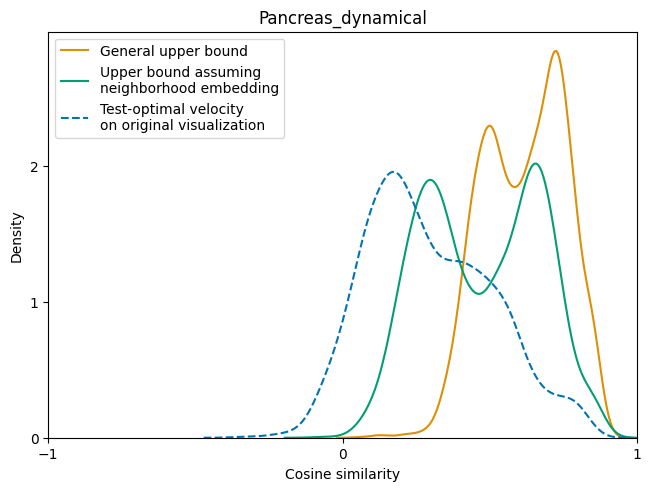

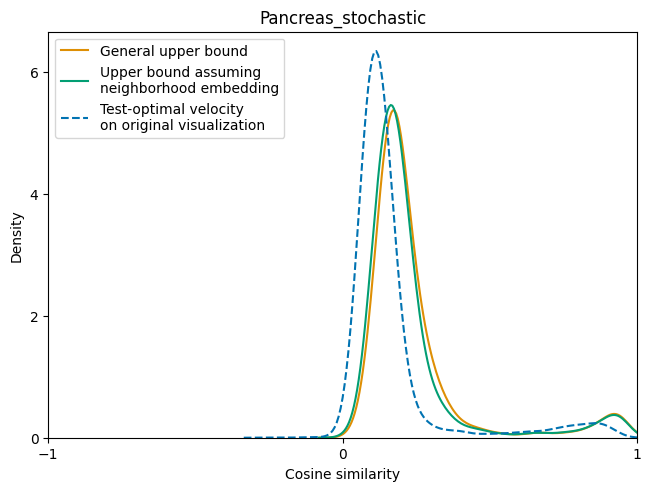

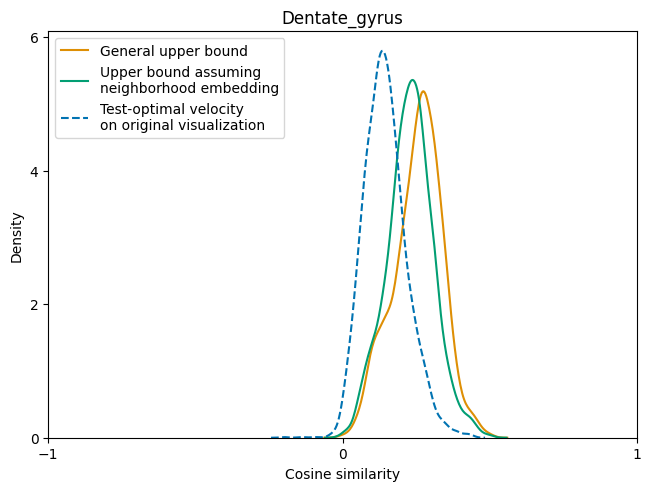

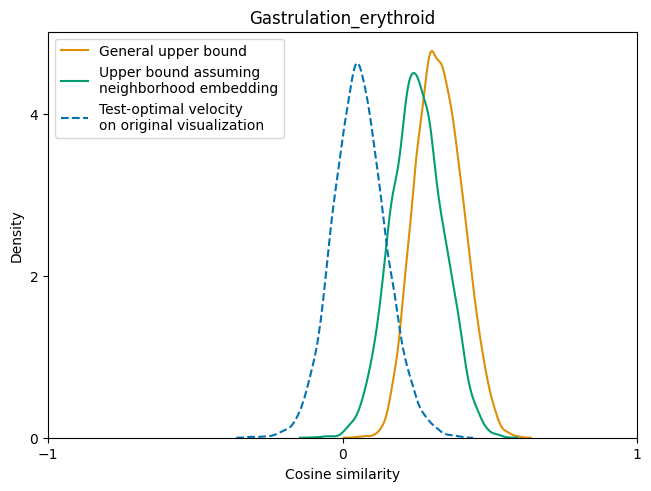

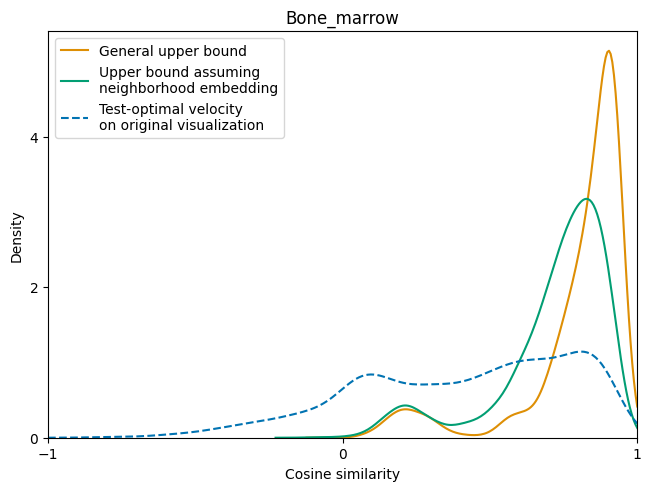

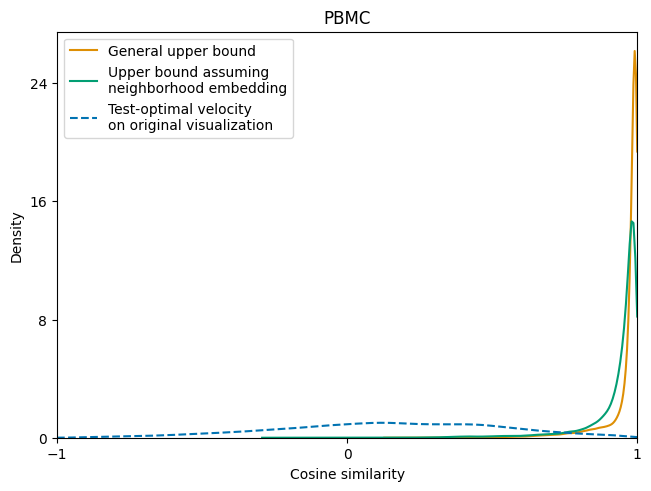

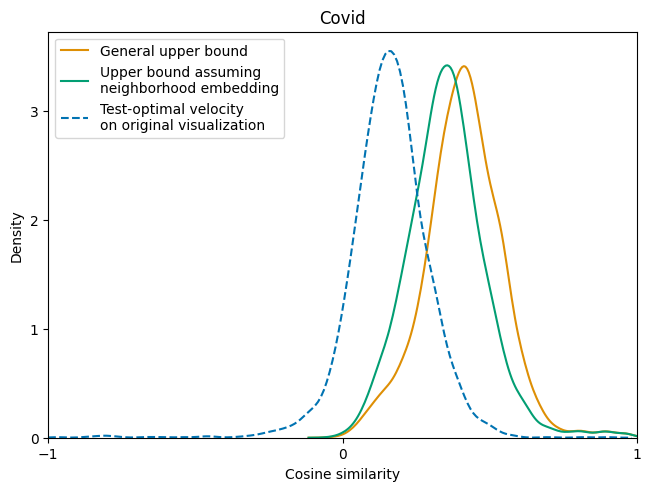

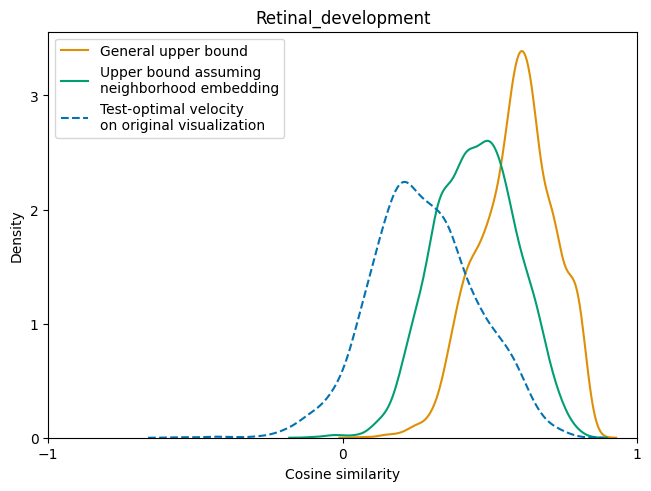

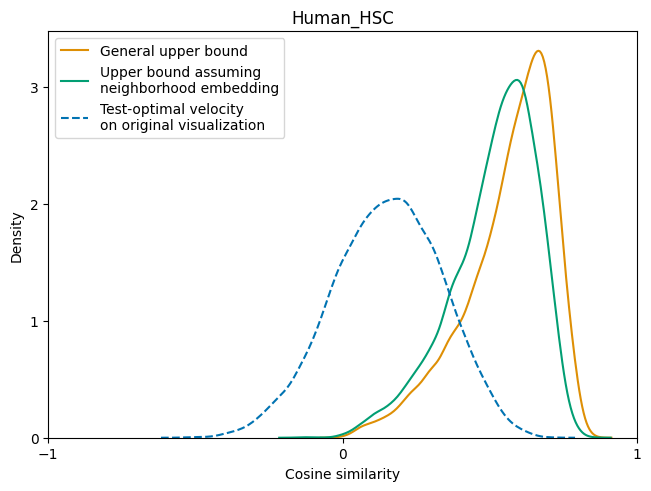

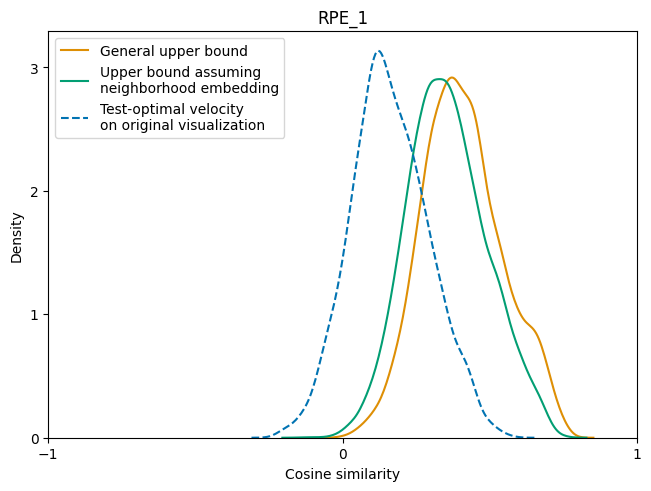

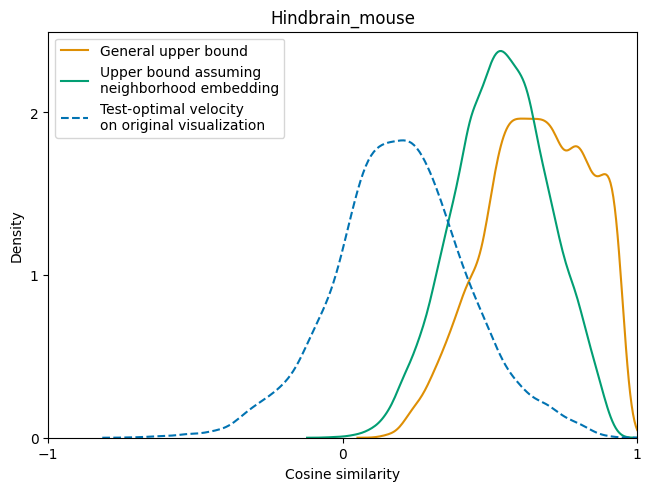

In [ ]:
# Plots were run and saved
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    plot_bounds(best, general, upper, best, best, name, limits=(-1, 1))

### Plot the test optimal velocity in 3 embeddings, PCA, t-SNE, UMAP

computing velocity embedding
    finished (0:00:08) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:10) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 384 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 36146/36146 [08:34<00:00, 70.25it/s] 


Exclusion radius in rad: 0.17453292519943295
Dropping all the genes which are not velocity genes. 384 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 36146/36146 [08:46<00:00, 68.71it/s] 


Exclusion radius in rad: 0.17453292519943295
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 592 genes left.
Number of workers:  9
Runnining with new modification


...

Exclusion radius in rad: 0.17453292519943295
computing velocity embedding
    finished (0:00:02) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:04) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [03:27<00:00, 77.22it/s] 


Exclusion radius in rad: 0.17453292519943295
Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [03:19<00:00, 80.46it/s] 


Exclusion radius in rad: 0.17453292519943295


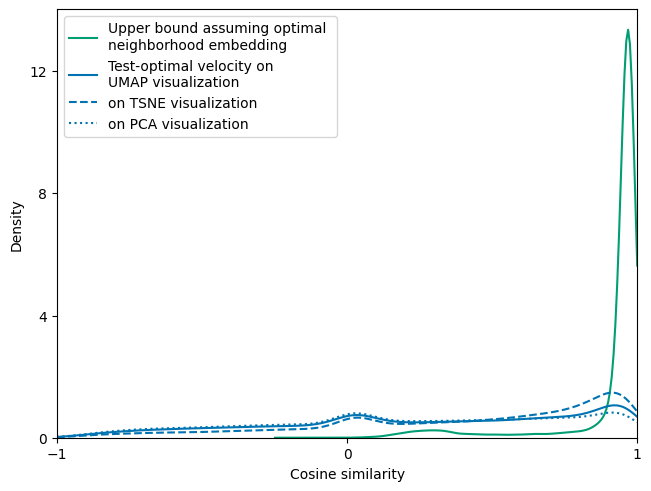

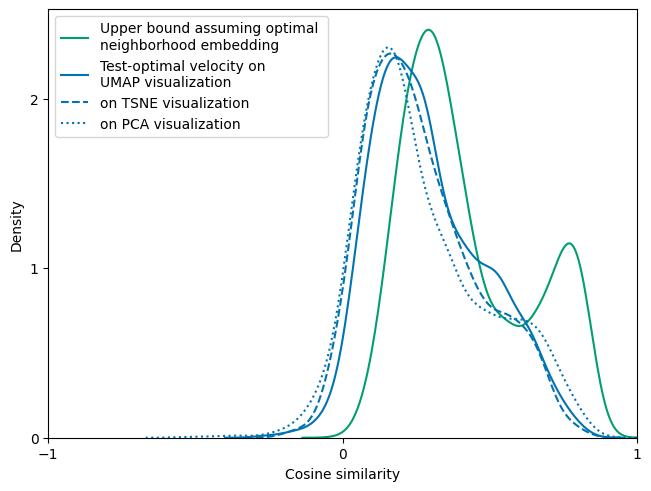

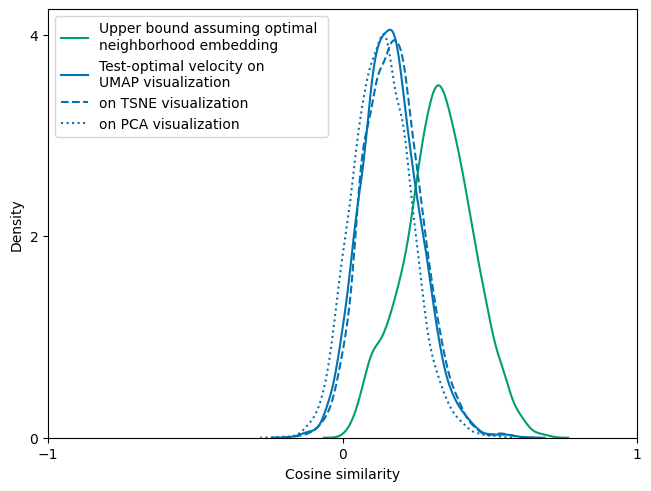

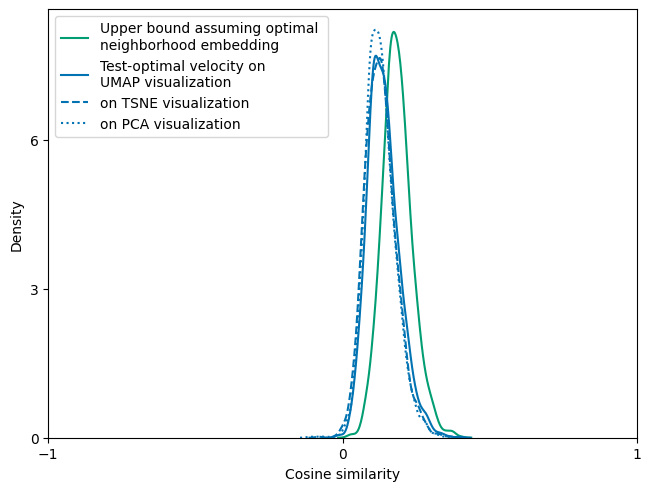

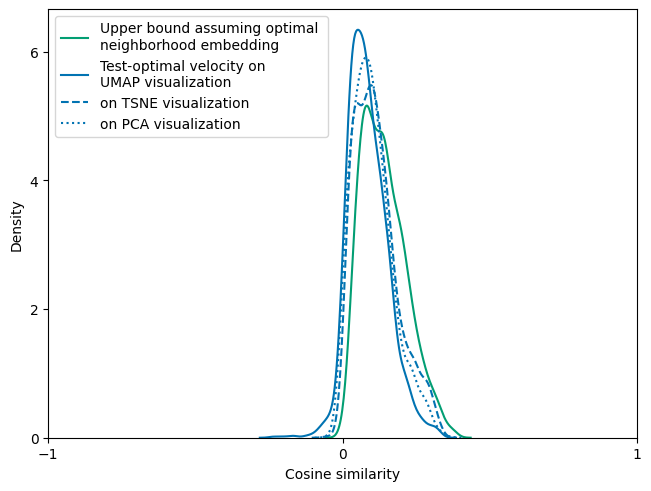

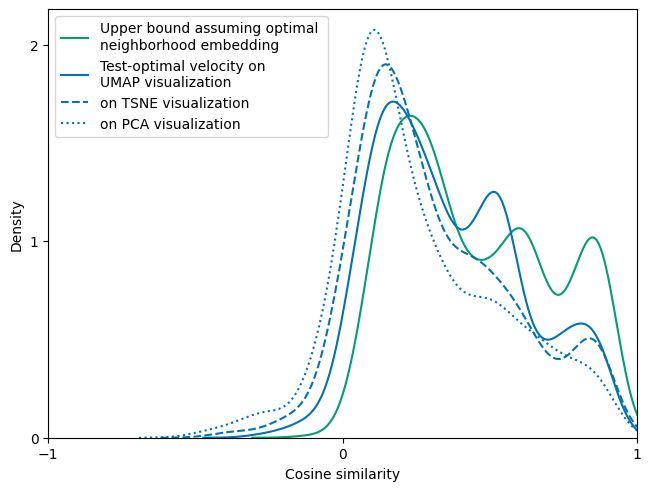

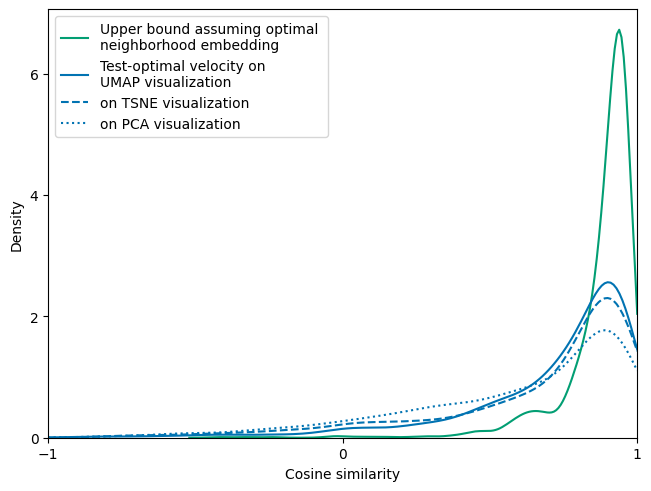

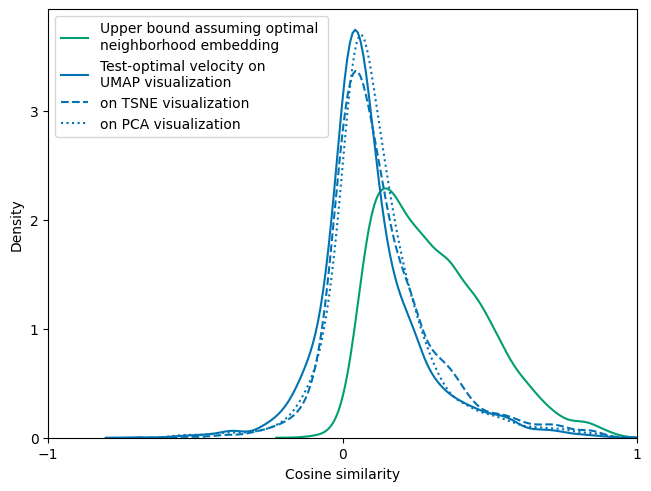

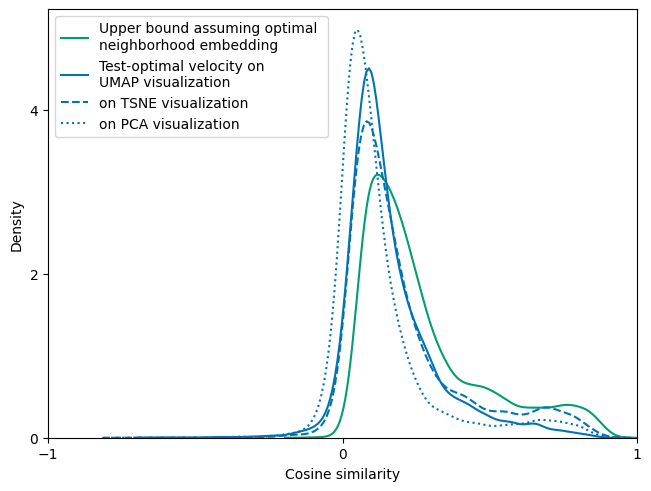

In [ ]:
# Plots were run and saved
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    basis = config['basis']
    if basis == "umap":
        umap = adata.uns['best_embedding']
        # Get tsne
        sc.tl.tsne(adata)
        scvelo.tl.velocity_embedding(adata, basis='tsne')
        scvelo.tl.velocity_embedding(adata, basis='pca')
        uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis="tsne", number_neighbors_to_sample_from=300, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
        statistics = debug_dict['statistics']
        tsne = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]
    if basis == "tsne":
        tsne = adata.uns['best_embedding']
        # Get umap
        sc.tl.umap(adata)
        scvelo.tl.velocity_embedding(adata, basis='umap')
        scvelo.tl.velocity_embedding(adata, basis='pca')
        uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis="umap", number_neighbors_to_sample_from=300, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
        statistics = debug_dict['statistics']
        umap = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    # get pca
    adata.obsm['X_pca'] = adata.obsm['X_pca'][:, :2]
    adata.obsm['velocity_pca'] = adata.obsm['velocity_pca'][:, :2]
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis="pca", number_neighbors_to_sample_from=300, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']
    pca = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    plot_embeddings(umap, tsne, pca, upper, name)

### Plot in the embedding the cells (50) with the highest/lowest potential to improve (distance of cos.similarity to high dimensional neighbor)

Dropping all the genes which are not velocity genes. 1038 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:23<00:00, 156.11it/s]


Exclusion radius in rad: 0.17453292519943295


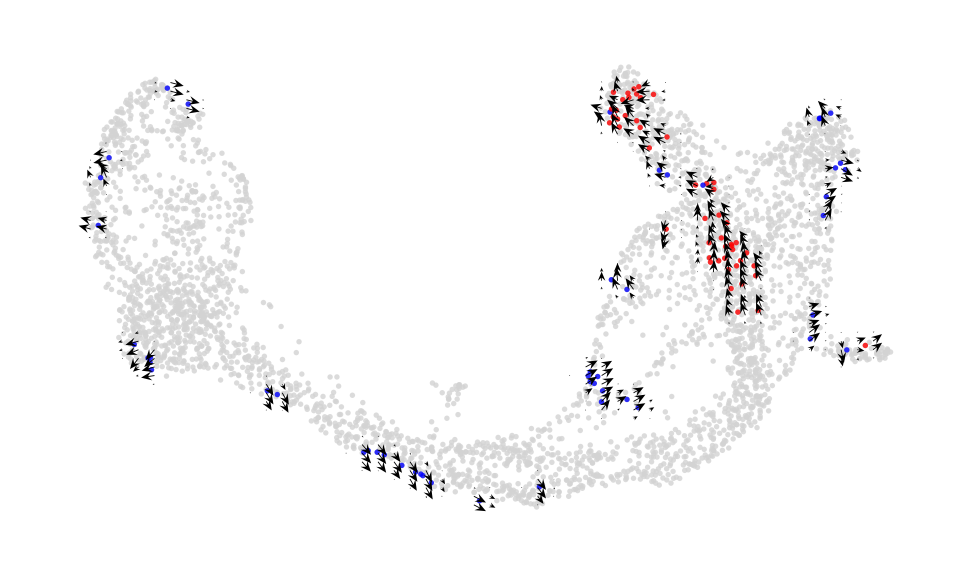

Dropping all the genes which are not velocity genes. 557 genes left.
Number of workers:  9
Runnining with new modification


  0%|          | 0/2930 [00:00<?, ?it/s]Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  0%|          | 0/2930 [00:01<?, ?it/s]  File "<string>", line 1, in <module>
  File "<string>", line 1, in <module>
  File "<string>", line 1, in <module>
  File "<string>", line 1, in <module>
  File "<string>", line 1, in <module>
  File "<string>", line 1, in <module>
  File "<string>", line 1, in <module>
Traceback (most recent call last):
  File "<string>", line 1, in <module>
Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/multiprocessing/spawn.py", line 116, in spawn_main
  File "/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/multiprocessing/spawn.py", line 116, in spawn_main
  

KeyboardInterrupt: 

In [9]:
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]

    dis = np.subtract(upper_n,best)
    high_indices = np.argpartition(dis, -50)[-50:]
    low_indices = np.argpartition(dis, 50)[:50]
    adata.obs['highlight'] = 'Other'
    subset_barcodes = adata.obs.index[non_empty_indices]

    high_barcodes = subset_barcodes[high_indices]
    low_barcodes = subset_barcodes[low_indices]
    adata.obs.loc[high_barcodes, 'highlight'] = 'Target Cells'
    adata.obs.loc[low_barcodes, 'highlight'] = 'Low Cells'
    adata_plot = bestVelocityEmbedded(adata, basis=basis, clusters=clusters, cluster_colors=cluster_colors)

    # Plotting
    cm = 1 / 2.54 
    figsize=(5 * cm, 4 * cm)
    fig, ax = plt.subplots(dpi=450, figsize=figsize)
    ax.set(xticks=[], yticks=[])
    pl = scvelo.pl.velocity_embedding_grid(adata_plot, 
                                    basis=basis, 
                                    color='highlight', 
                                    groups=['Low Cells', 'Target Cells'], 
                                    palette={'Target Cells': 'red', 'Other': 'lightgrey', 'Low Cells': 'blue'},
                                    show=False, size=3,rasterized=True, figsize=figsize,alpha=0.8,
                                    ax=ax, frameon=False, xlabel='', ylabel='', title ='',
                                    arrow_color='black', edgecolors=None,
                                    linewidth=.25, arrow_size=2, arrow_length=1, )
    ax.set_aspect('equal')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    pl.set_rasterized(True)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_highlighted_cells_50.pdf", transparent=True, dpi=450)
    plt.show()

## Plot the cells that have a distance below 0 (so are better embedded now that in their upper bound)

Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 150.61it/s]


Exclusion radius in rad: 0.17453292519943295


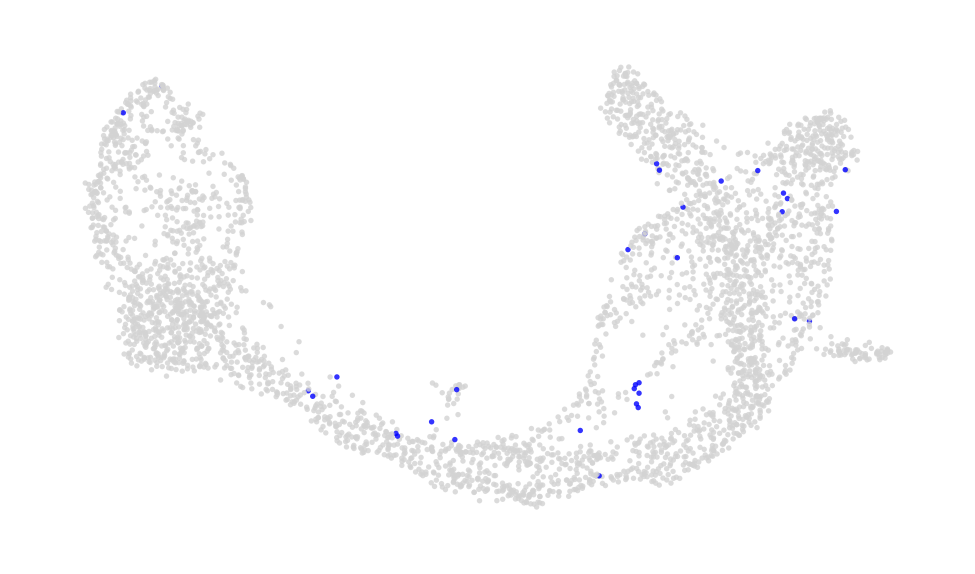

Dropping all the genes which are not velocity genes. 1038 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 148.49it/s]


Exclusion radius in rad: 0.17453292519943295


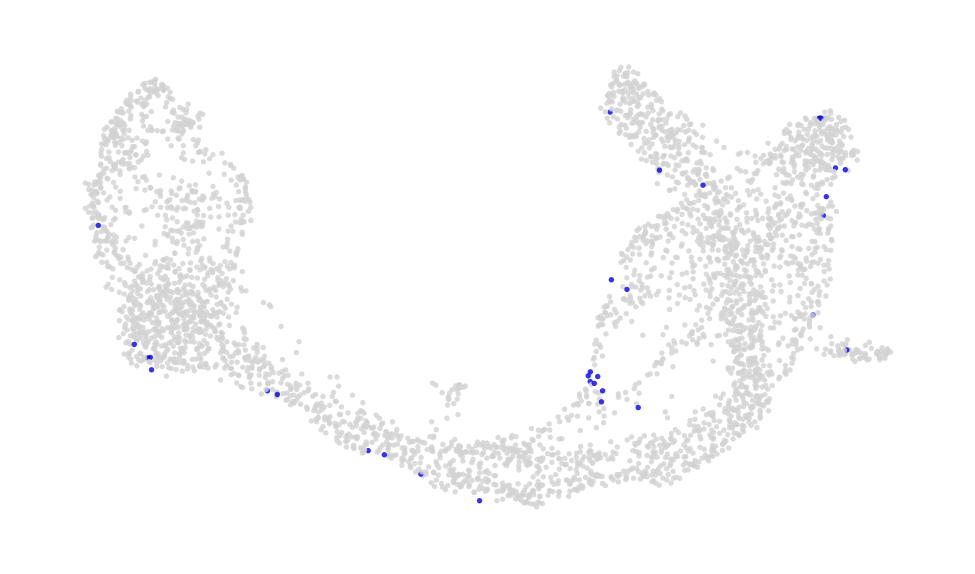

Dropping all the genes which are not velocity genes. 557 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2930/2930 [00:20<00:00, 145.36it/s]


Exclusion radius in rad: 0.17453292519943295


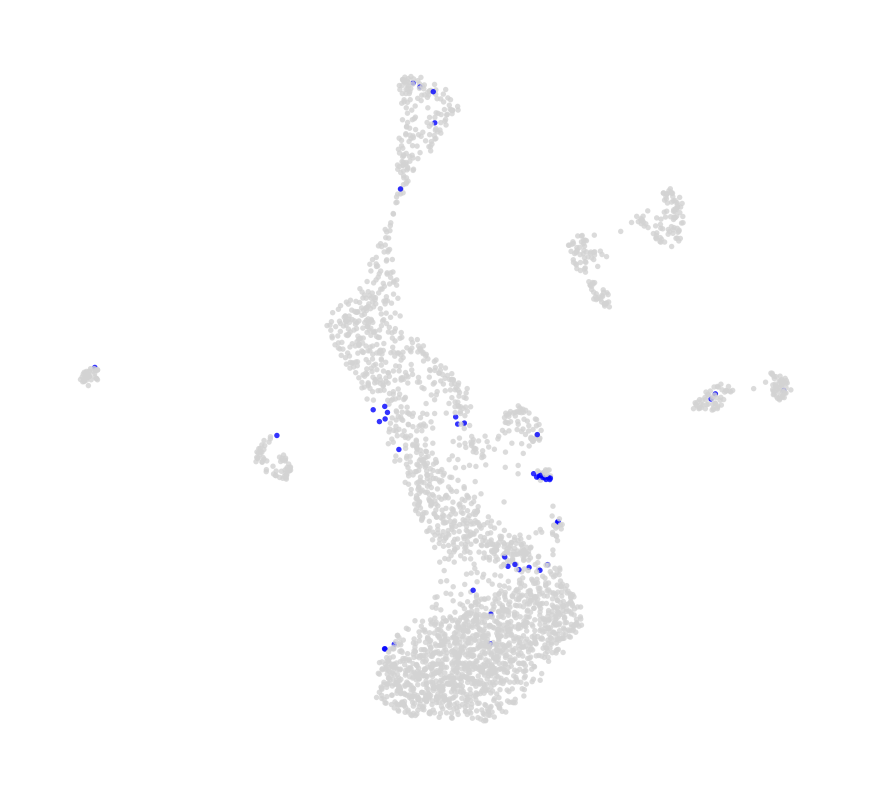

Dropping all the genes which are not velocity genes. 488 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 9815/9815 [01:07<00:00, 146.42it/s]


Exclusion radius in rad: 0.17453292519943295


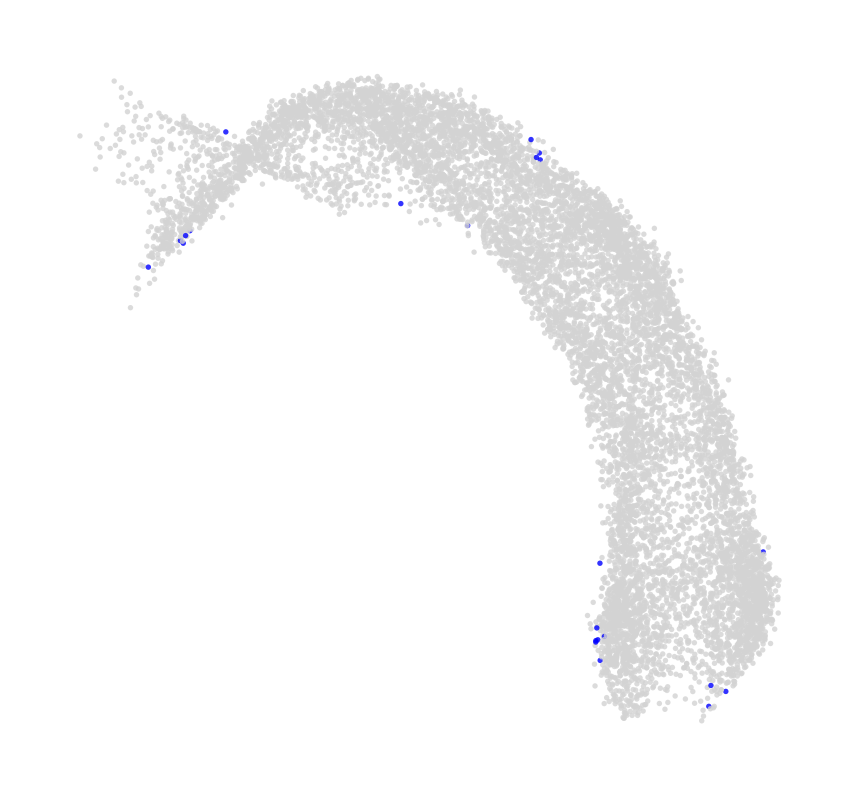

Dropping all the genes which are not velocity genes. 451 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 5780/5780 [00:36<00:00, 158.35it/s]


Exclusion radius in rad: 0.17453292519943295


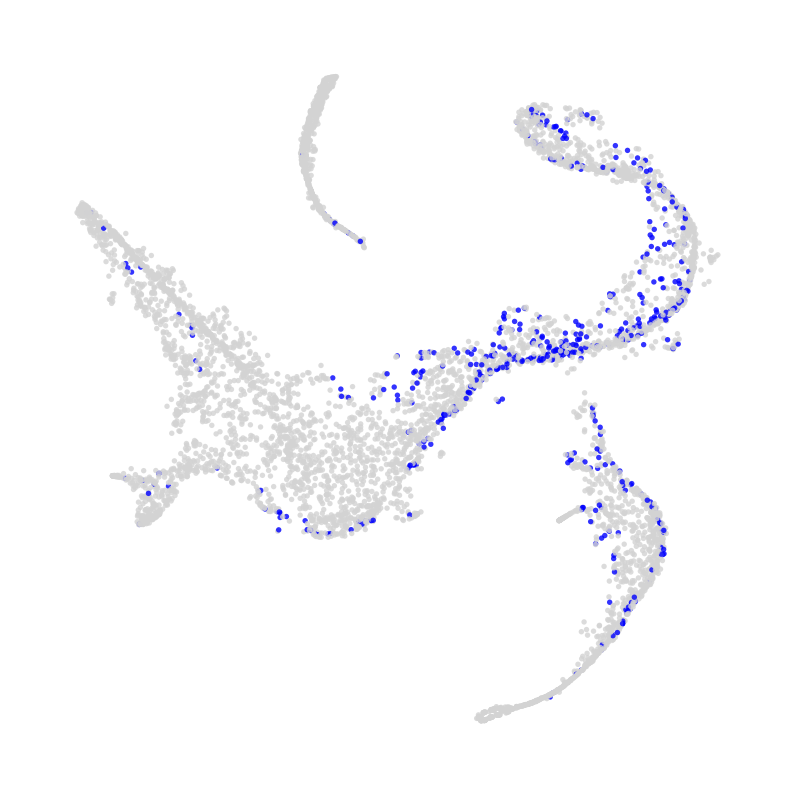

Dropping all the genes which are not velocity genes. 126 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3076/3076 [00:19<00:00, 154.44it/s]


Exclusion radius in rad: 0.17453292519943295


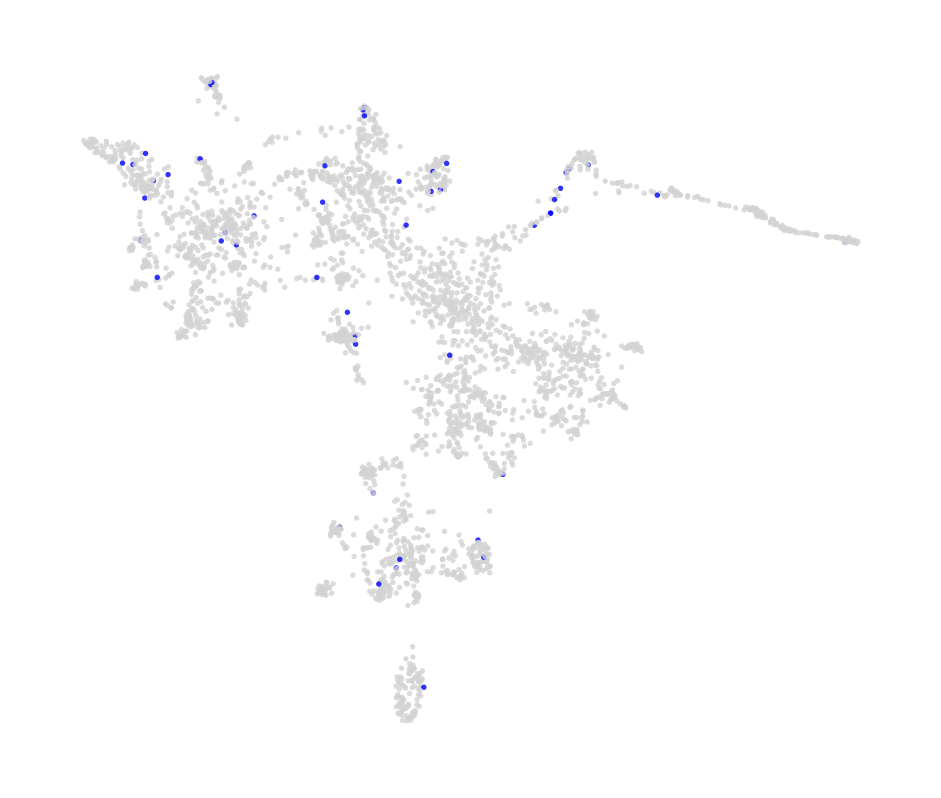

Dropping all the genes which are not velocity genes. 677 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2726/2726 [00:17<00:00, 151.59it/s]


Exclusion radius in rad: 0.17453292519943295


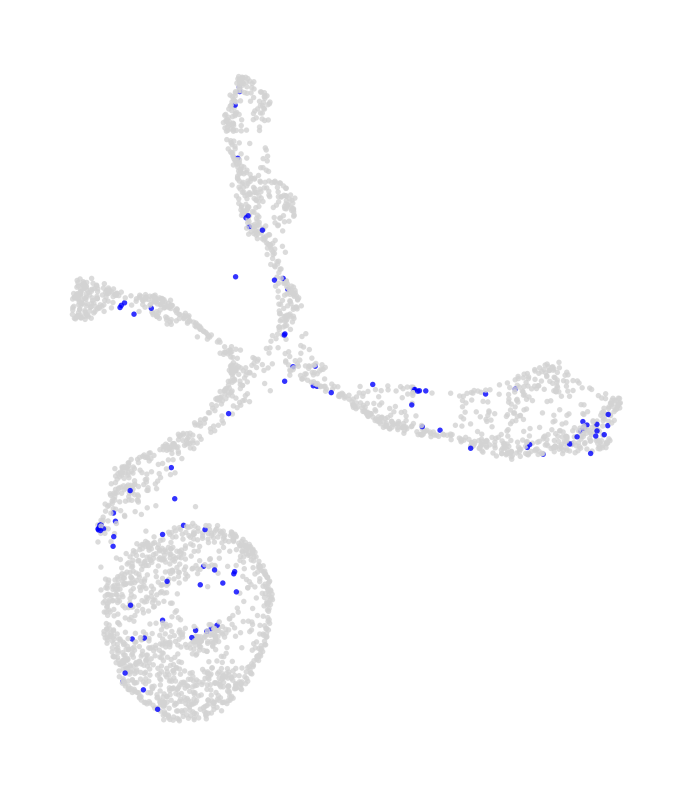

Dropping all the genes which are not velocity genes. 328 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 11605/11605 [01:16<00:00, 151.57it/s]


Exclusion radius in rad: 0.17453292519943295


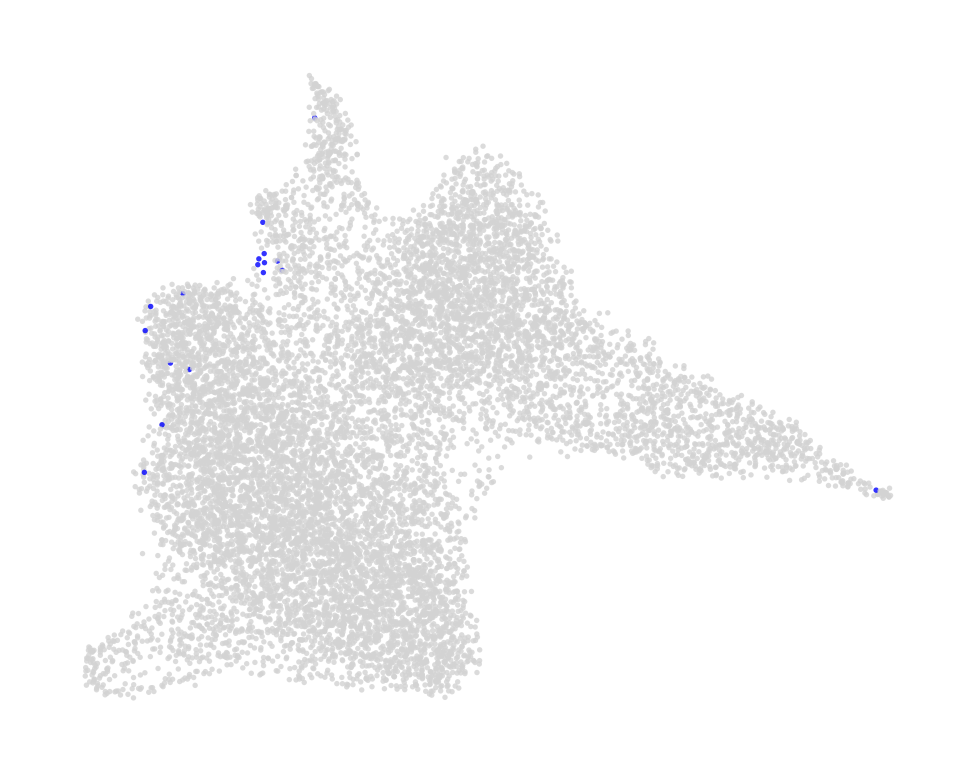

Dropping all the genes which are not velocity genes. 387 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 5422/5422 [00:35<00:00, 153.74it/s]


Exclusion radius in rad: 0.17453292519943295


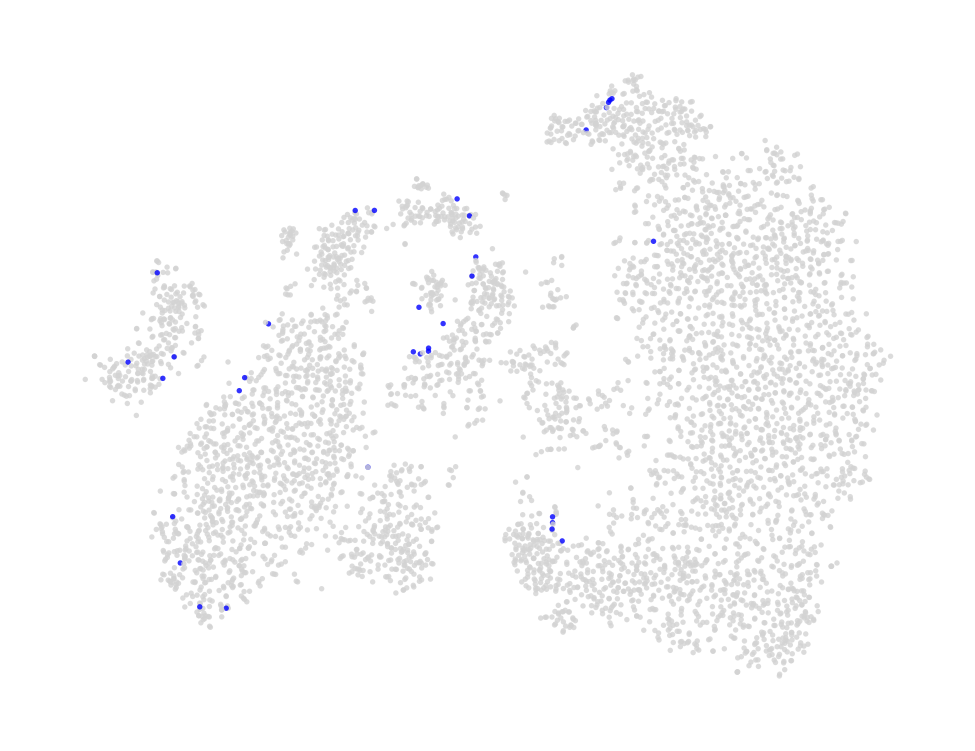

Dropping all the genes which are not velocity genes. 288 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 13501/13501 [01:33<00:00, 143.81it/s]


Exclusion radius in rad: 0.17453292519943295


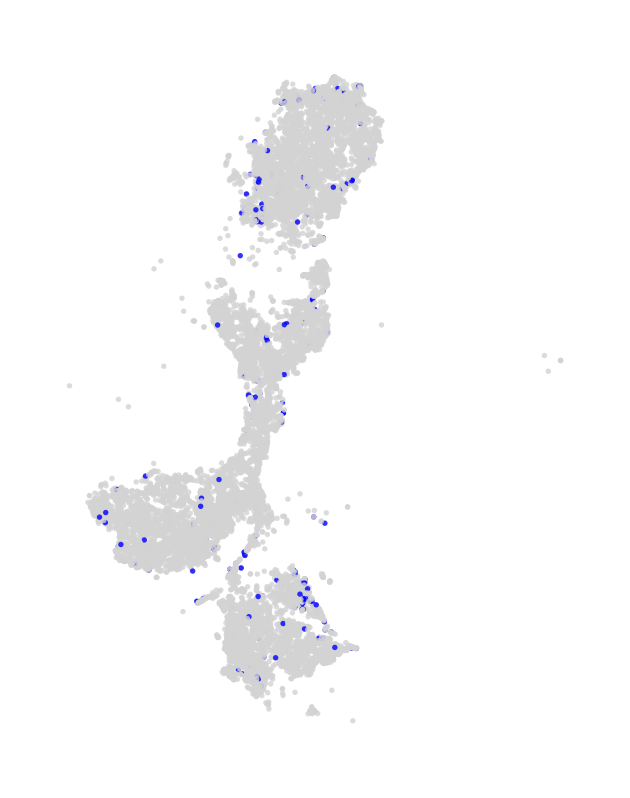

Dropping all the genes which are not velocity genes. 592 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2600/2600 [00:17<00:00, 148.06it/s]


Exclusion radius in rad: 0.17453292519943295


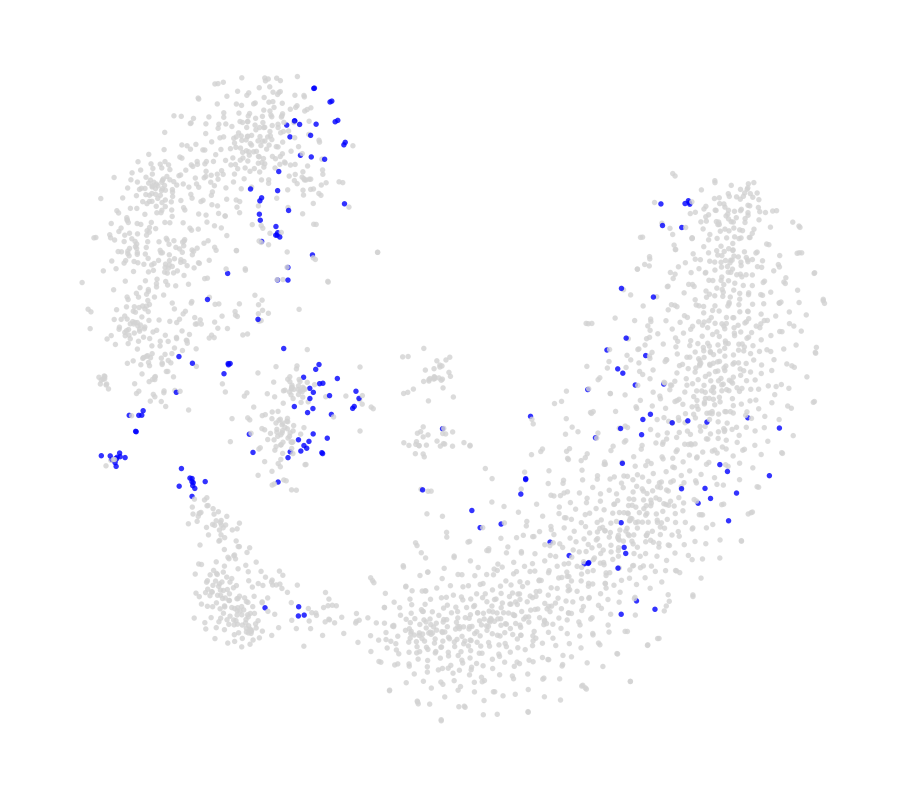

Dropping all the genes which are not velocity genes. 351 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 4693/4693 [00:34<00:00, 134.62it/s]


Exclusion radius in rad: 0.17453292519943295


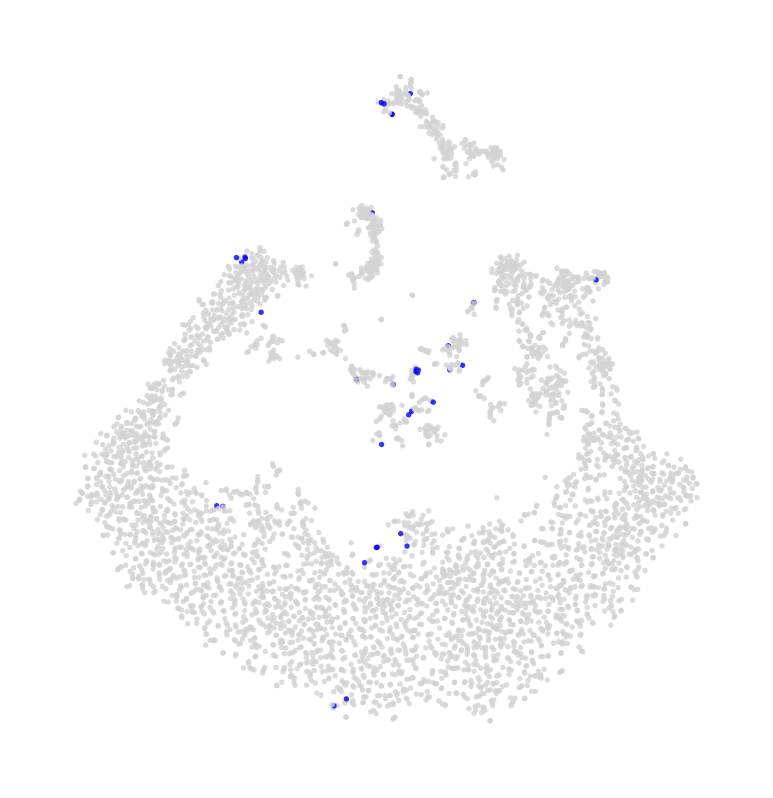

Dropping all the genes which are not velocity genes. 1218 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1772/1772 [00:12<00:00, 138.77it/s]


Exclusion radius in rad: 0.17453292519943295


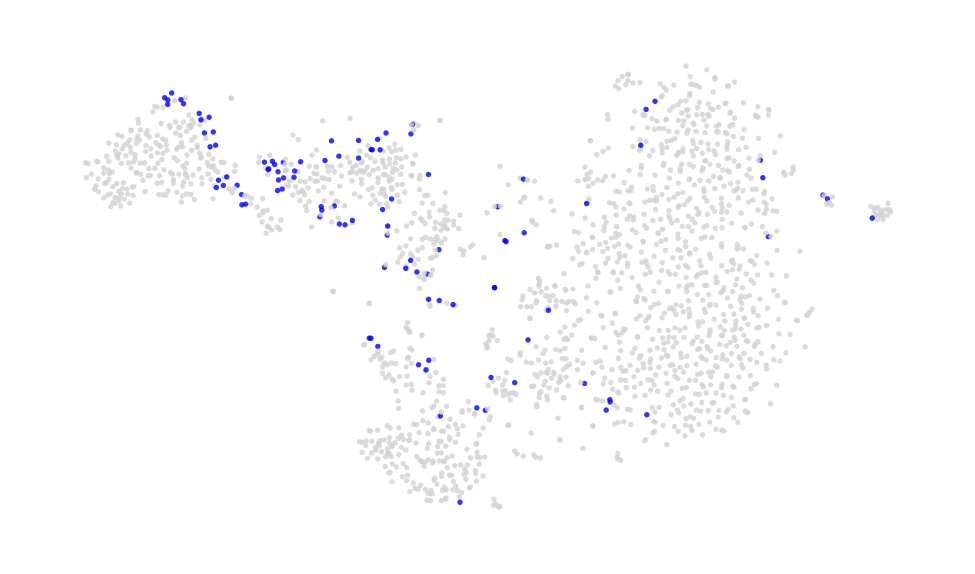

Dropping all the genes which are not velocity genes. 299 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1829/1829 [00:12<00:00, 141.93it/s]


Exclusion radius in rad: 0.17453292519943295


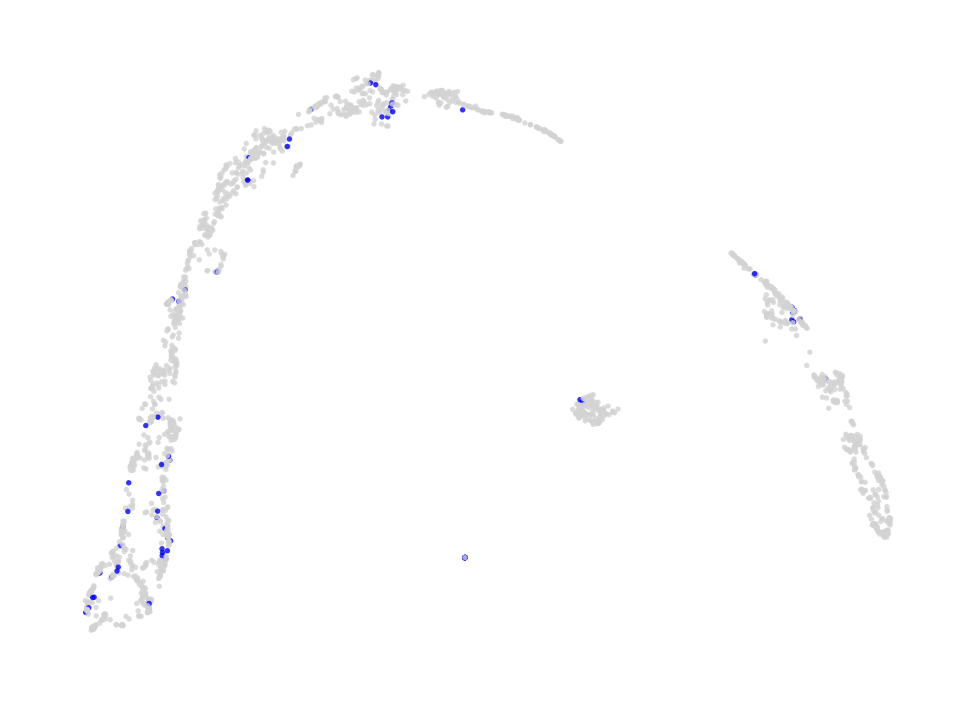

Dropping all the genes which are not velocity genes. 1302 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1823/1823 [00:12<00:00, 143.08it/s]


Exclusion radius in rad: 0.17453292519943295


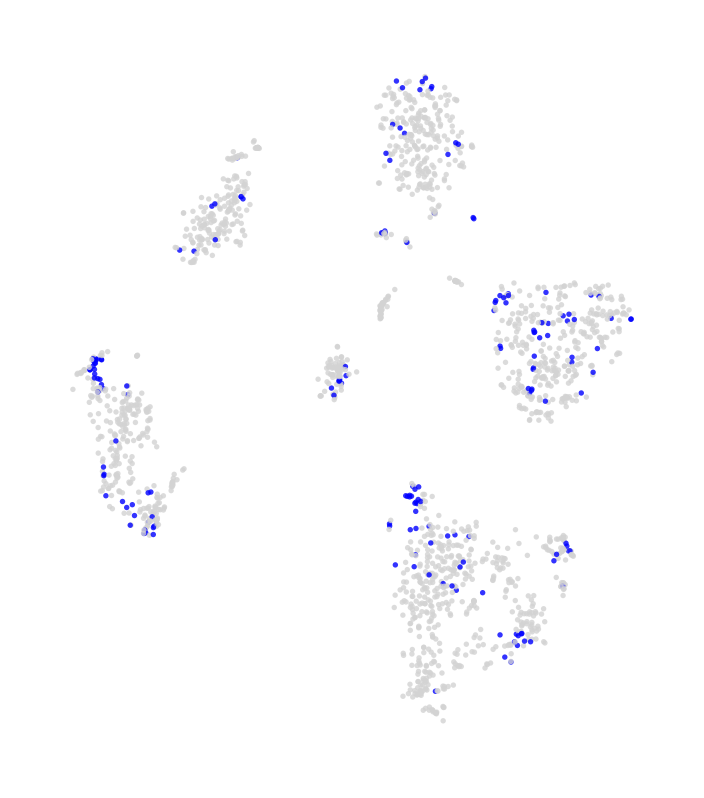

Dropping all the genes which are not velocity genes. 1232 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1267/1267 [00:09<00:00, 137.03it/s]


Exclusion radius in rad: 0.17453292519943295


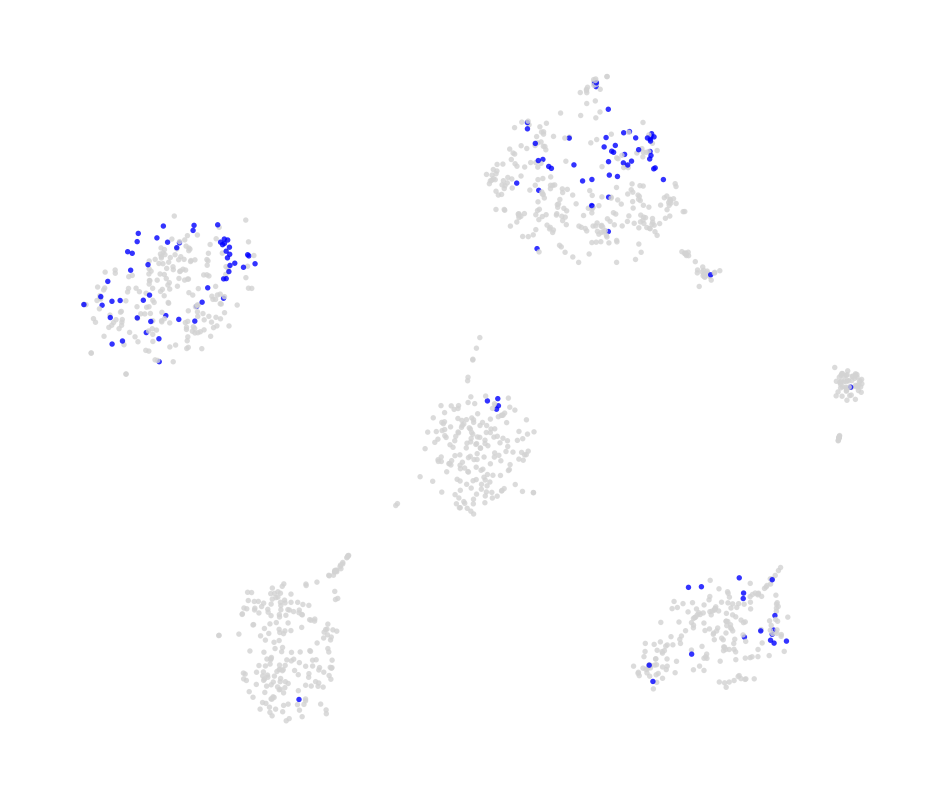

Dropping all the genes which are not velocity genes. 156 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3831/3831 [00:25<00:00, 152.47it/s]


Exclusion radius in rad: 0.17453292519943295


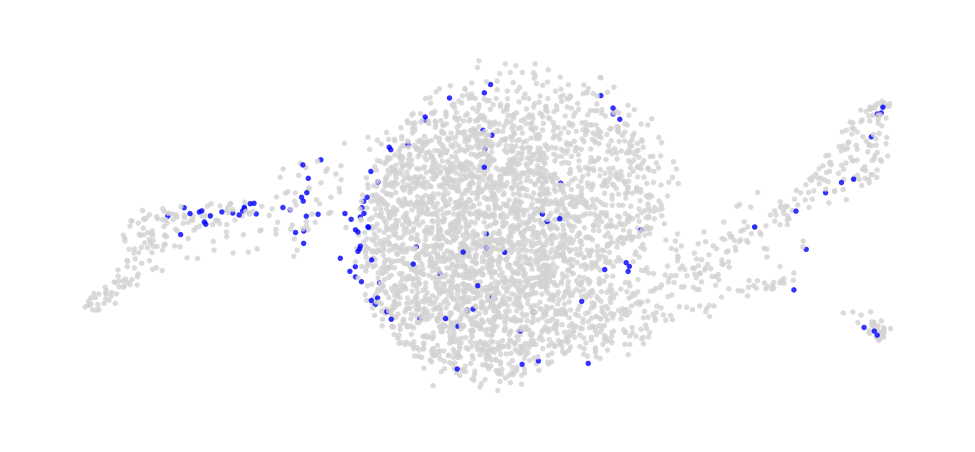

Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [01:57<00:00, 136.42it/s]


Exclusion radius in rad: 0.17453292519943295


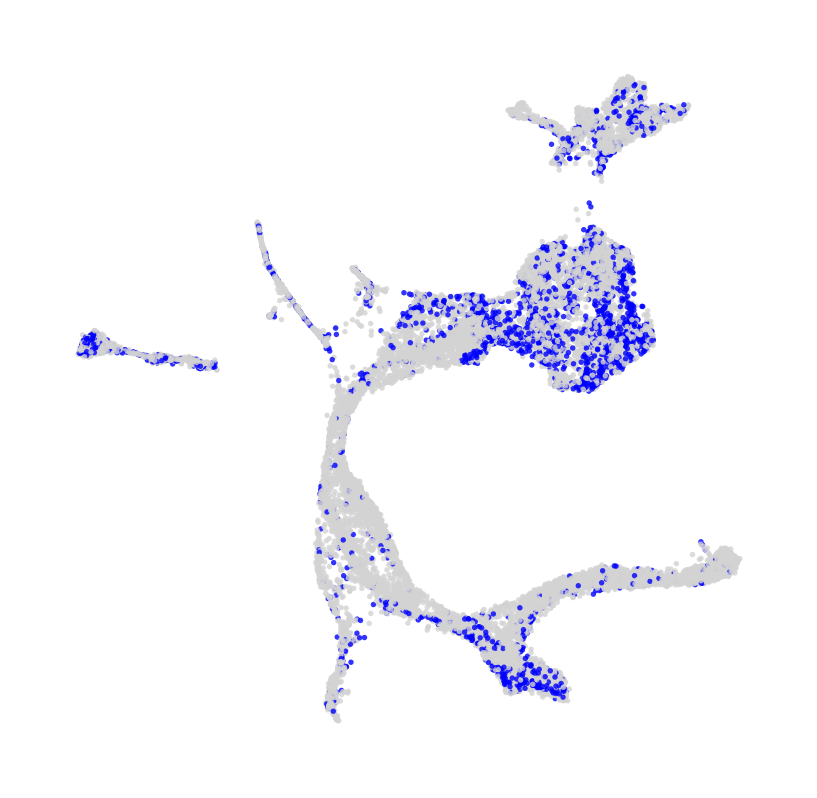

In [7]:
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]

    dis = np.subtract(upper_n,best)
    below_zero_indices = np.where(dis < 0)[0]
    if len(below_zero_indices) == 0:
        print(f"Skipping {name}: 0 cells found below zero.")
        continue
    adata.obs['highlight'] = 'Other'
    subset_barcodes = adata.obs.index[non_empty_indices]

    below_zero_barcodes = subset_barcodes[below_zero_indices]
    adata.obs.loc[below_zero_barcodes, 'highlight'] = 'Target Cells'
    adata_plot = bestVelocityEmbedded(adata, basis=basis, clusters=clusters, cluster_colors=cluster_colors)

    # Plotting
    cm = 1 / 2.54 
    figsize=(5 * cm, 4 * cm)
    fig, ax = plt.subplots(dpi=450, figsize=figsize)
    ax.set(xticks=[], yticks=[])
    pl = scvelo.pl.scatter(adata_plot, 
                                    basis=basis, 
                                    color='highlight', 
                                    palette={'Target Cells': 'blue', 'Other': 'lightgrey'},
                                    show=False, size=3,rasterized=True, figsize=figsize,alpha=0.8,
                                    ax=ax, frameon=False, xlabel='', ylabel='', title ='', legend_loc='none')
    ax.set_aspect('equal')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    pl.set_rasterized(True)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_highlighted_below_0.pdf", transparent=True, dpi=450)
    plt.show()

## Plot smaller bound plots 

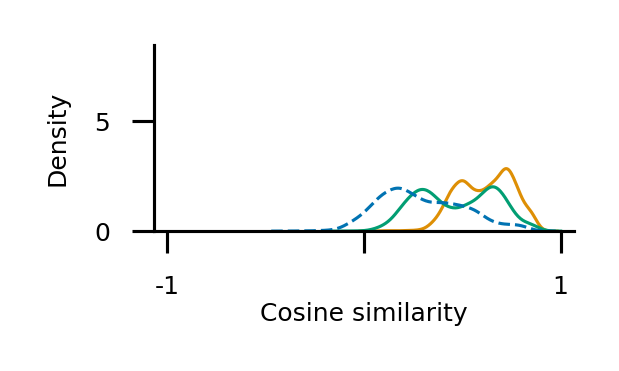

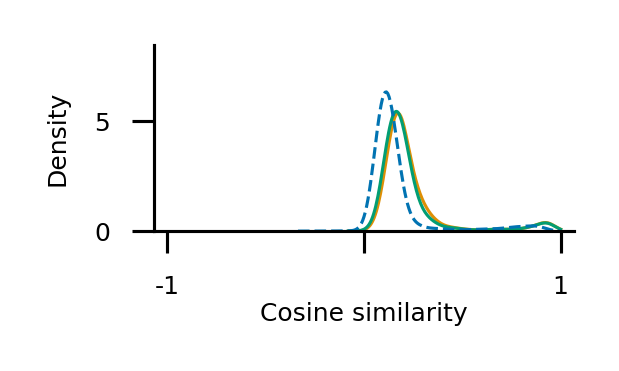

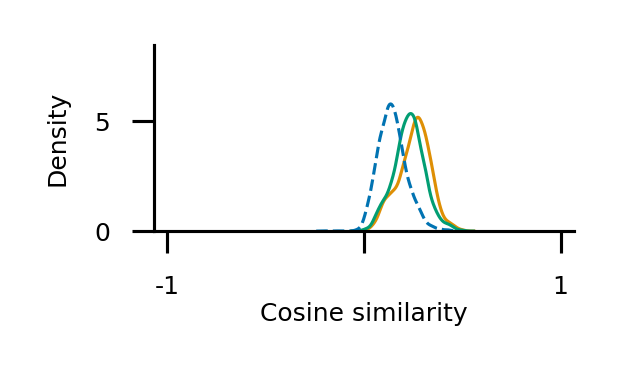

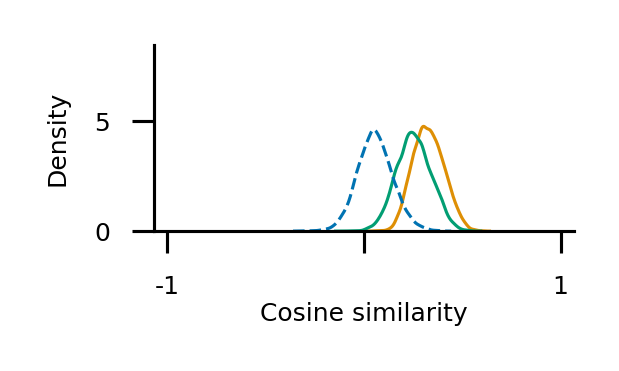

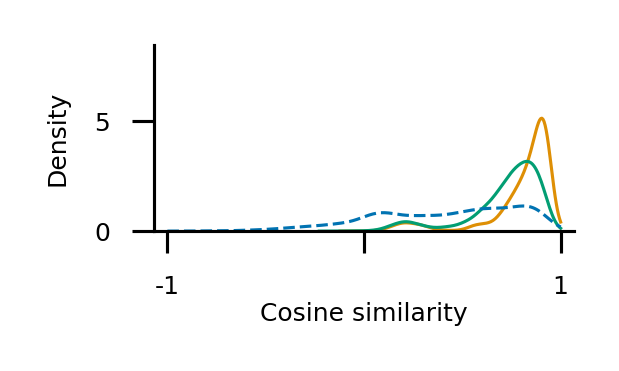

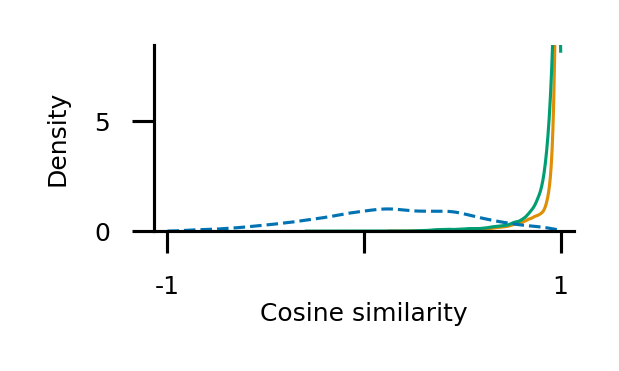

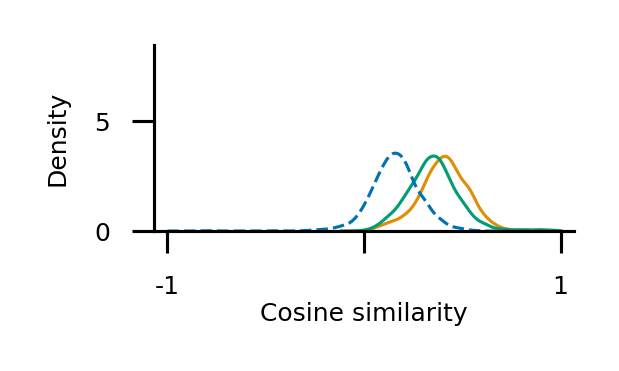

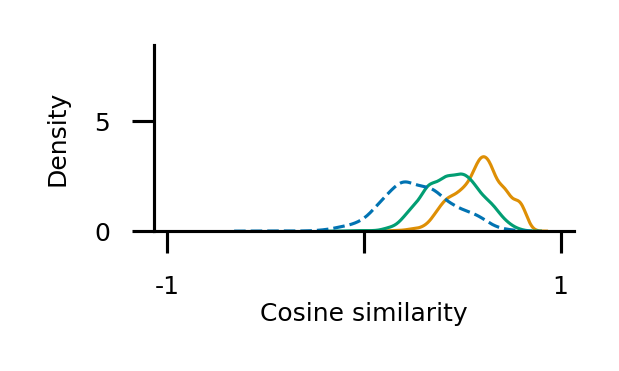

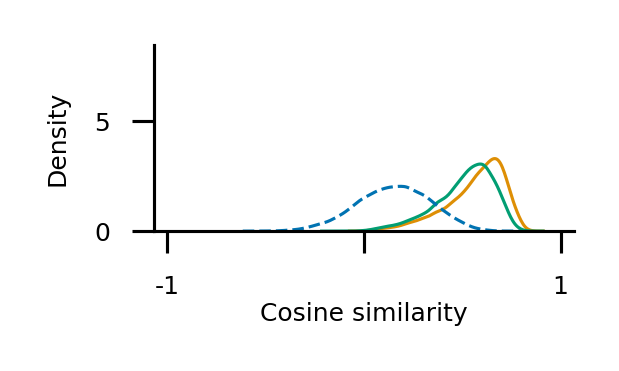

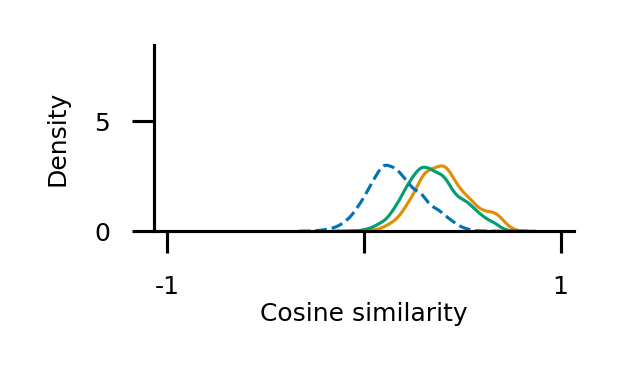

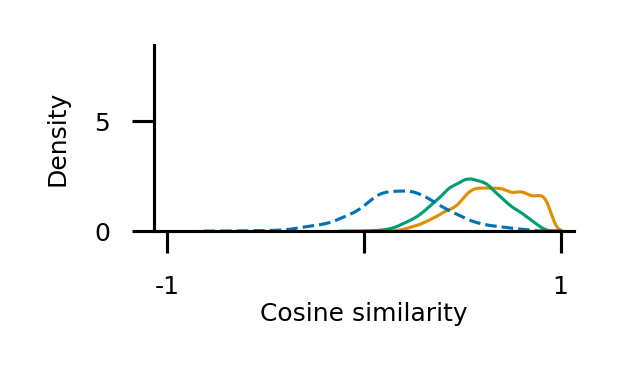

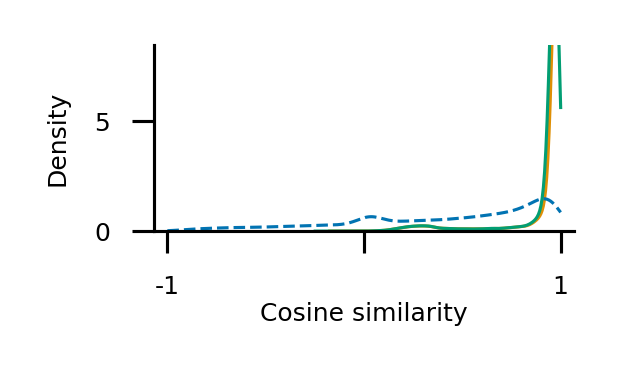

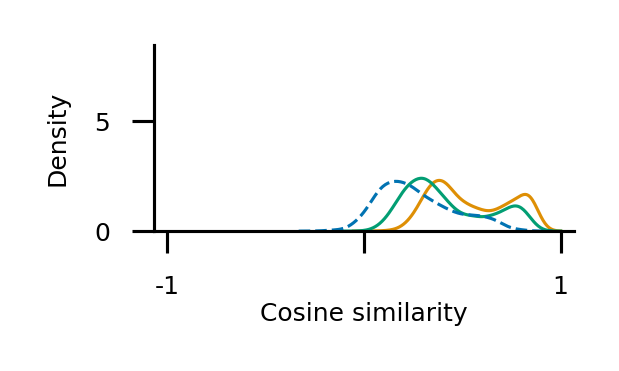

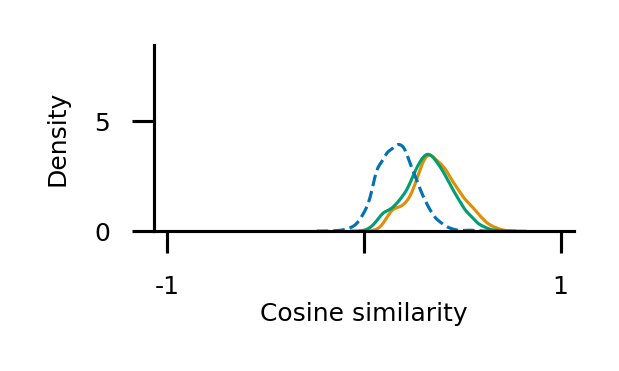

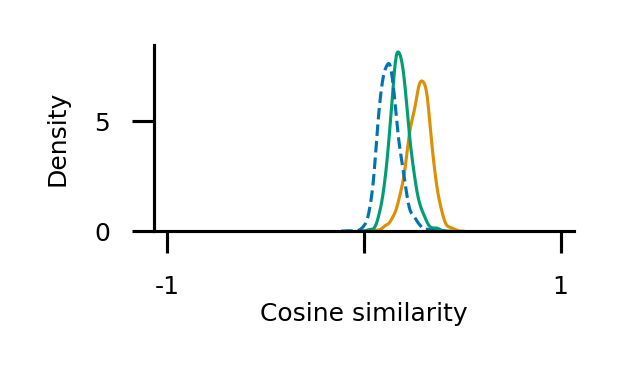

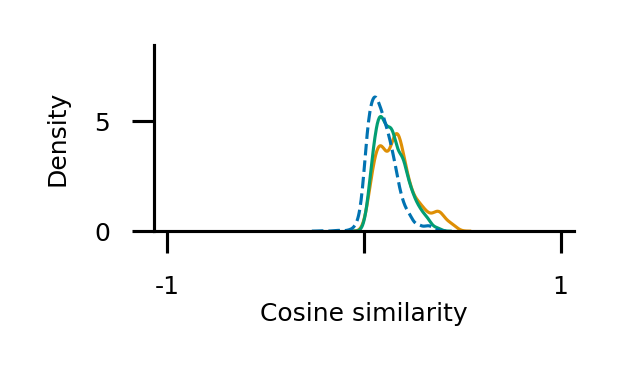

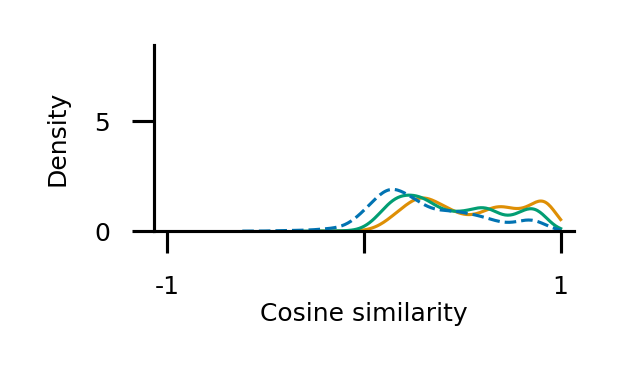

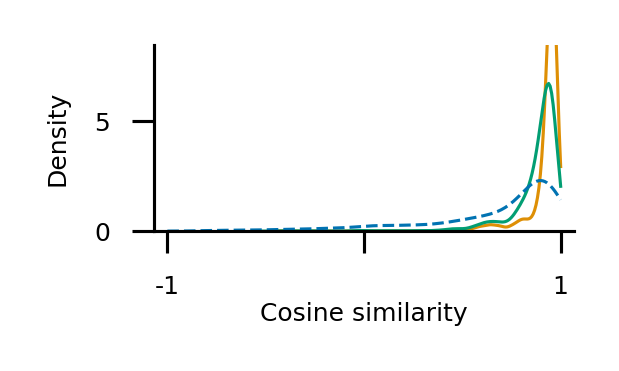

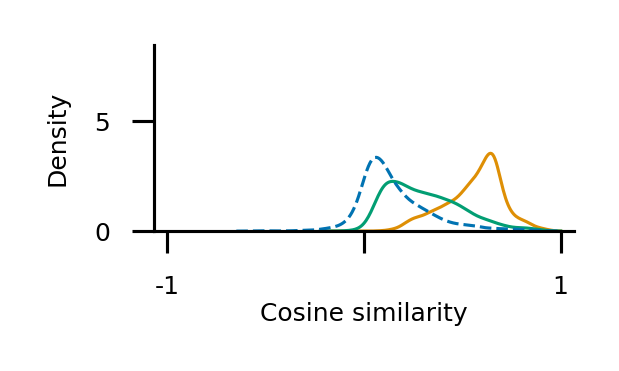

In [ ]:
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]

    cm = 1 / 2.54 
    figsize=(3.2 * cm, 1.8 * cm)
    fig, ax = plt.subplots(dpi=450, constrained_layout=True, figsize=figsize)
    palette = sns.color_palette("colorblind", 5)
    ax.set_prop_cycle(color=palette)

    sns.kdeplot(general, clip=(-1, 1), fill=False, label="General upper bound", color=palette[1],linewidth=0.5)
    sns.kdeplot(upper, clip=(-1, 1), fill=False, color=palette[2], label="Upper bound assuming \nneighborhood embedding", linewidth=0.5)  # mean over top k of all
    sns.kdeplot(best, clip=(-1, 1), fill=False, label="Test-optimal velocity \non original visualization", linestyle="--", color=palette[0], linewidth=0.5)
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))

    ax.set_xticks([-1, 0, 1], labels=[-1, "", 1], fontsize=4)
    ax.tick_params(axis='both', width=0.5, labelsize=4)
    ax.yaxis.set_major_locator(plt.MaxNLocator(2))

    ax.spines["left"].set_linewidth(0.5)
    ax.spines["bottom"].set_linewidth(0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.xlim(-1.07, 1.07)

    plt.ylim(top=8.5)
    plt.xlabel("Cosine similarity", fontsize=4, labelpad=0.5)
    plt.ylabel("Density", fontsize=4)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_bound_small.pdf", transparent=True, dpi=450)

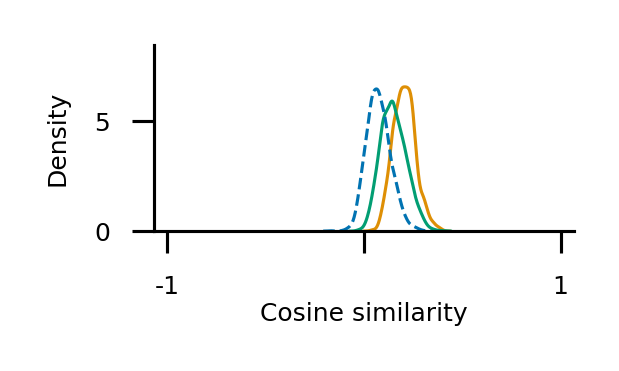

In [10]:

adata = sc.read("/mnt/volume/Johanna_Velotest/sim_data/dynamical_linear_2000_cells_500_genes_350_total_80_points_seed_42.h5ad") 
general = adata.obsm['general_bound']
upper = adata.obsm['upper_max_neighbors'] 
best = adata.uns['best_embedding']
non_empty_indices = adata.uns['non_empty_indices']
upper_n = upper[non_empty_indices]

cm = 1 / 2.54 
figsize=(3.2 * cm, 1.8 * cm)
fig, ax = plt.subplots(dpi=450, constrained_layout=True, figsize=figsize)
palette = sns.color_palette("colorblind", 5)
ax.set_prop_cycle(color=palette)

sns.kdeplot(general, clip=(-1, 1), fill=False, label="General upper bound", color=palette[1],linewidth=0.5)
sns.kdeplot(upper, clip=(-1, 1), fill=False, color=palette[2], label="Upper bound assuming \nneighborhood embedding", linewidth=0.5)  # mean over top k of all
sns.kdeplot(best, clip=(-1, 1), fill=False, label="Test-optimal velocity \non original visualization", linestyle="--", color=palette[0], linewidth=0.5)
ax.xaxis.set_major_locator(plt.MaxNLocator(3))

ax.set_xticks([-1, 0, 1], labels=[-1, "", 1], fontsize=4)
ax.tick_params(axis='both', width=0.5, labelsize=4)
ax.yaxis.set_major_locator(plt.MaxNLocator(2))

ax.spines["left"].set_linewidth(0.5)
ax.spines["bottom"].set_linewidth(0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xlim(-1.07, 1.07)

plt.ylim(top=8.5)
plt.xlabel("Cosine similarity", fontsize=4, labelpad=0.5)
plt.ylabel("Density", fontsize=4)
plt.savefig("/mnt/volume/Johanna_Velotest/results/bounds/Dyngen_Seed42_bound.pdf", transparent=True, dpi=450)